<a href="https://colab.research.google.com/github/fabianmoore/MineriaDatos/blob/main/Actividad_2_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: Clustering por partición (K-means) y jerárquico

- Ejercicio 1: K-means para segmentar clientes (Mall Customers).
- Ejercicio 2: dendrograma para ver con qué países se agrupa Chile (Country data).

In [1]:
import os, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

SEED = 42          # semilla común para que todo sea reproducible
sns.set_theme()

# Ejercicio 1 · K-means: segmentar clientes de una tienda

## Carga de datos
Se descarga con "kagglehub". Las credenciales están en los Secretos de Colab ("KAGGLE_API_TOKEN", o bien "KAGGLE_USERNAME" y "KAGGLE_KEY"), así no quedan escritas en el notebook. No se asume el nombre del archivo: se lista la carpeta y se busca el CSV.

In [2]:
# [DESCARGA]
import kagglehub
from google.colab import userdata

# Pasa a variables de entorno los secretos de Kaggle que existan (sirve para token nuevo o usuario + clave)
for nombre in ["KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN", "KAGGLE_API_KEY"]:
    try:
        os.environ[nombre] = userdata.get(nombre)
    except Exception:
        pass   # ese secreto no existe: se sigue con los demás

ruta1 = pathlib.Path(kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python"))
print(sorted(p.name for p in ruta1.rglob("*")))
csv1 = next(ruta1.rglob("Mall_Customers.csv"))

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
['Mall_Customers.csv']


## Paso 1 · Hipótesis antes de calcular
Primero se carga el CSV y se grafica ingreso vs. puntaje de gasto sin colorear y sin ningún algoritmo.

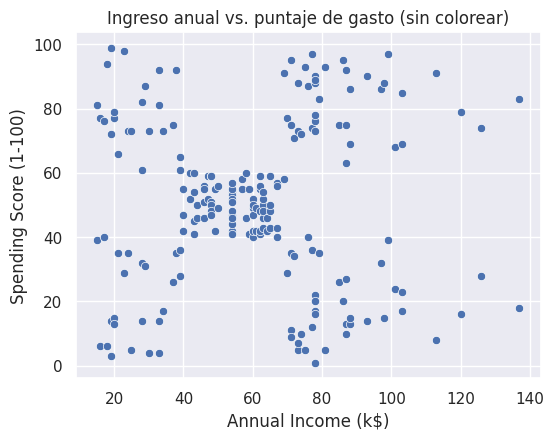

In [3]:
df = pd.read_csv(csv1)
plt.figure(figsize=(6, 4.5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.title("Ingreso anual vs. puntaje de gasto (sin colorear)")
plt.show()

**Hipótesis inicial: 5 grupos.**

Evidencia visual: se ve una nube compacta al centro (ingreso y gasto medios) y cuatro nubes en las esquinas del gráfico (ingreso bajo/alto × gasto bajo/alto), separadas por zonas vacías.

## Paso 2 · Explorar





(200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Gender
Female    112
Male       88
Name: count, dtype: int64


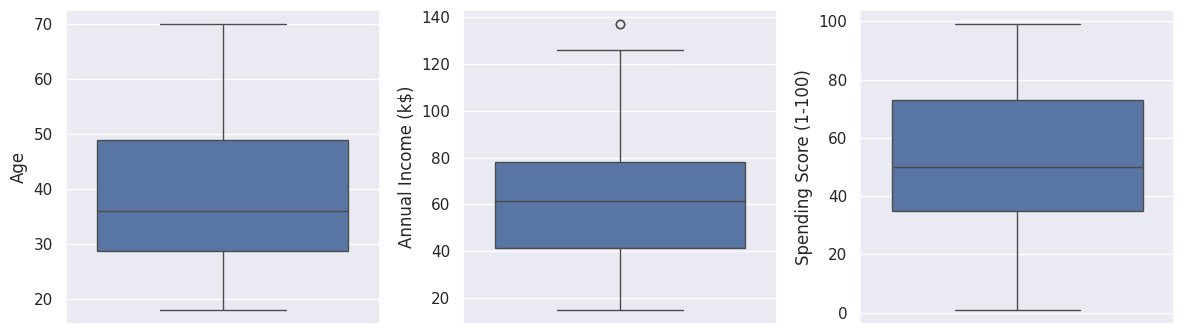

In [4]:
print(df.shape)
df.info()
print(df.isna().sum())
display(df.describe())
print(df["Gender"].value_counts())

cols_num = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, c in zip(ax, cols_num):
    sns.boxplot(y=df[c], ax=a)
plt.tight_layout(); plt.show()

**Unidad de análisis:** un cliente (una fila).

**Decisiones sobre variables:**
- "CustomerID" es solo un identificador; su número no mide nada del cliente. Si entrara a la distancia, clientes con ID cercano parecerían «parecidos» sin razón. Se excluye.
- "Gender" es categórica. Codificada como 0/1, la distancia euclidiana solo vería «0 o 1 de diferencia», un salto fijo y arbitrario que no se compara bien con ingreso o puntaje. Se excluye del modelo y solo se podría usar para describir grupos después.
- "Age" se deja fuera de la primera versión para poder graficar en 2D. El modelo parte con ingreso y puntaje de gasto.


## Paso 3 · Preparar: variables y escala

In [5]:
features1 = ["Annual Income (k$)", "Spending Score (1-100)"]
X1 = df[features1].copy()                       # versión sin estandarizar
print(X1.agg(["min", "max"]))

scaler1 = StandardScaler()
X1_std = pd.DataFrame(scaler1.fit_transform(X1), columns=features1, index=df.index)  # versión estandarizada
print(X1_std.agg(["mean", "std"]).round(2))

     Annual Income (k$)  Spending Score (1-100)
min                  15                       1
max                 137                      99
      Annual Income (k$)  Spending Score (1-100)
mean                -0.0                    -0.0
std                  1.0                     1.0


Rangos antes de escalar: ingreso ≈ 15–137 (k$) y puntaje de gasto ≈ 1–99.

Decisión: estandarizar. Los rangos son parecidos, así que aquí el efecto será pequeño, pero estandarizar es una buena práctica: K-means usa distancia euclidiana y no queremos que una variable pese más solo por sus unidades.

## Paso 4 · Ajustar K-means y explorar k

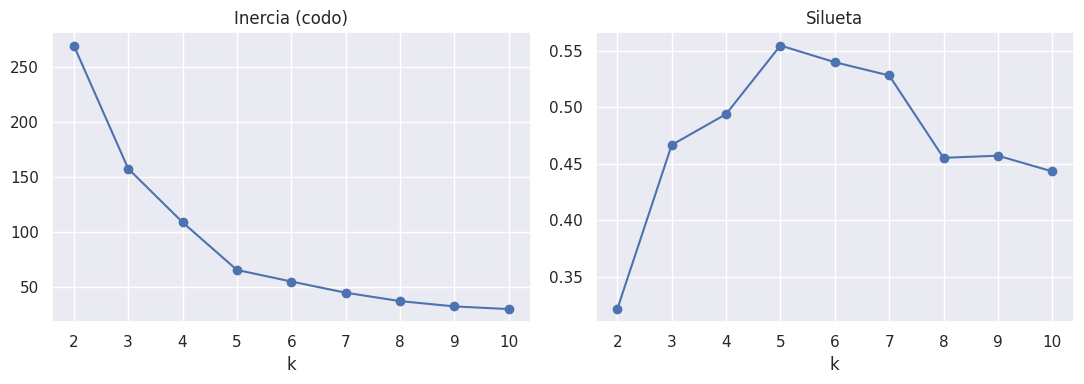

,k,inercia,silueta
0,2,269.691,0.321
1,3,157.704,0.467
2,4,108.921,0.494
3,5,65.568,0.555
4,6,55.057,0.540
5,7,44.865,0.528
6,8,37.228,0.455
7,9,32.392,0.457
8,10,29.982,0.443


In [6]:
ks = range(2, 11)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X1_std)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X1_std, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inercia, "o-"); ax[0].set_title("Inercia (codo)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), silueta, "o-"); ax[1].set_title("Silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

pd.DataFrame({"k": list(ks), "inercia": inercia, "silueta": silueta}).round(3)

¿Por qué la inercia siempre baja al subir k? La inercia es la suma de distancias cuadráticas de cada punto a su centroide. Con más centroides, cada punto tiene uno más cercano, así que la suma solo puede bajar (con k = n sería 0). Por eso no sirve elegir k mirando solo esa curva: siempre "mejora". Hay que buscar el punto donde la mejora se vuelve pequeña (codo) y apoyarse en otras evidencias.

## Paso 5 · Evaluar con más de una evidencia

In [7]:
K1 = 5
km_ref = KMeans(n_clusters=K1, n_init=10, random_state=SEED).fit(X1_std)

# (b) Estabilidad 1: distintas semillas con una sola inicialización
aris = []
for s in range(10):
    km_s = KMeans(n_clusters=K1, n_init=1, random_state=s).fit(X1_std)
    aris.append(adjusted_rand_score(km_ref.labels_, km_s.labels_))
print("ARI por semilla vs. referencia:", np.round(aris, 3))

# (b) Estabilidad 2: ajustar con 80 % de los clientes y asignar al resto
sub80 = X1_std.sample(frac=0.8, random_state=SEED)
km_sub = KMeans(n_clusters=K1, n_init=10, random_state=SEED).fit(sub80)
print("ARI submuestra 80 %:", round(adjusted_rand_score(km_ref.labels_, km_sub.predict(X1_std)), 3))

# Mini-experimento de escala: mismo k con y sin estandarizar
km_raw = KMeans(n_clusters=K1, n_init=10, random_state=SEED).fit(X1)
print("ARI sin estandarizar vs. estandarizado:", round(adjusted_rand_score(km_ref.labels_, km_raw.labels_), 3))
print(pd.crosstab(km_ref.labels_, km_raw.labels_, rownames=["estandarizado"], colnames=["sin estandarizar"]))
print("Tamaños estandarizado:", np.bincount(km_ref.labels_), "| sin estandarizar:", np.bincount(km_raw.labels_))

ARI por semilla vs. referencia: [1.    0.985 1.    0.985 0.692 0.985 0.985 1.    0.703 1.   ]
ARI submuestra 80 %: 0.985
ARI sin estandarizar vs. estandarizado: 1.0
sin estandarizar   0   1   2   3   4
estandarizado                       
0                 81   0   0   0   0
1                  0  39   0   0   0
2                  0   0  22   0   0
3                  0   0   0  35   0
4                  0   0   0   0  23
Tamaños estandarizado: [81 39 22 35 23] | sin estandarizar: [81 39 22 35 23]


k elegido: 5. Evidencias:
1. Estructura interna: el codo de la inercia se aplana alrededor de k = 5 y la silueta alcanza su valor más alto en k = 5.
2. Estabilidad: con otras semillas y con una submuestra del 80 %, los grupos casi no cambian (ARI cercano a 1). Una semilla aislada con "n_init=1" puede caer en un mal óptimo local; por eso se usa "n_init=10" en el modelo final.
3. Utilidad: los 5 grupos se pueden describir con lenguaje simple (ver paso 6) y cada uno admite una acción distinta.

Con vs. sin estandarizar: como ingreso y puntaje tienen rangos parecidos, se espera que los grupos cambien poco (ARI alto). Si las escalas fueran muy distintas, la variable de mayor rango dominaría la distancia y los grupos se formarían casi solo por ella.

## Paso 6 · Interpretar y decidir

,n,edad_media,ingreso_medio,ingreso_mediana,gasto_medio,gasto_mediana,segmento,accion_a_probar
cluster,,,,,,,,
0,81,42.7,55.3,54.0,49.5,50.0,Clientes promedio,Promociones generales por correo y cupón para ...
1,39,32.7,86.5,79.0,82.1,83.0,Clientes premium,Acceso anticipado a nuevas colecciones y progr...
2,22,25.3,25.7,24.5,79.4,77.0,Gasto alto con ingreso bajo,Puntos de fidelidad y ofertas por temporada (e...
3,35,41.1,88.2,85.0,17.1,16.0,"Alto ingreso, poco gasto",Encuesta corta y recomendaciones personalizada...
4,23,45.2,26.3,25.0,20.9,17.0,Clientes cautelosos,Cupones de descuento en productos básicos


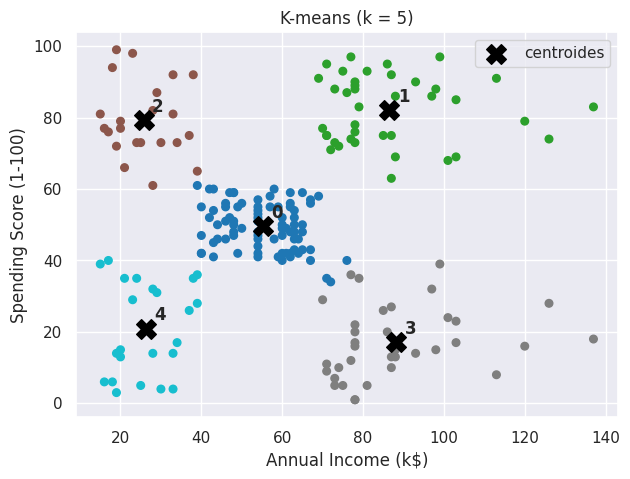

In [8]:
df["cluster"] = km_ref.labels_

perfil = df.groupby("cluster").agg(
    n=("CustomerID", "count"),
    edad_media=("Age", "mean"),
    ingreso_medio=("Annual Income (k$)", "mean"),
    ingreso_mediana=("Annual Income (k$)", "median"),
    gasto_medio=("Spending Score (1-100)", "mean"),
    gasto_mediana=("Spending Score (1-100)", "median"),
).round(1)

def nivel(v, bajo, alto):
    return "bajo" if v < bajo else ("alto" if v > alto else "medio")

nombres = {
    ("alto", "alto"): "Clientes premium",
    ("alto", "bajo"): "Alto ingreso, poco gasto",
    ("medio", "medio"): "Clientes promedio",
    ("bajo", "alto"): "Gasto alto con ingreso bajo",
    ("bajo", "bajo"): "Clientes cautelosos",
}
acciones = {
    "Clientes premium": "Acceso anticipado a nuevas colecciones y programa de fidelidad",
    "Alto ingreso, poco gasto": "Encuesta corta y recomendaciones personalizadas para activar la compra",
    "Clientes promedio": "Promociones generales por correo y cupón para una segunda compra",
    "Gasto alto con ingreso bajo": "Puntos de fidelidad y ofertas por temporada (evitar incentivar sobreendeudamiento)",
    "Clientes cautelosos": "Cupones de descuento en productos básicos",
}
perfil["segmento"] = [
    nombres.get((nivel(r.ingreso_medio, 40, 70), nivel(r.gasto_medio, 40, 60)), "Otro (revisar perfil)")
    for r in perfil.itertuples()
]
perfil["accion_a_probar"] = perfil["segmento"].map(acciones)
display(perfil)

# Centroides en unidades originales
centros = scaler1.inverse_transform(km_ref.cluster_centers_)

plt.figure(figsize=(7, 5))
plt.scatter(df[features1[0]], df[features1[1]], c=df["cluster"], cmap="tab10", s=30)
plt.scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=200, label="centroides")
for i, (x, y) in enumerate(centros):
    plt.annotate(str(i), (x, y), xytext=(6, 6), textcoords="offset points", fontweight="bold")
plt.xlabel(features1[0]); plt.ylabel(features1[1]); plt.legend(); plt.title("K-means (k = 5)")
plt.show()

Segmentos y acción a probar: cada grupo se nombra según su ingreso y gasto medio, y recibe una acción distinta para testear (por ejemplo, con A/B).

Reflexión final del ejercicio 1:
- ¿Coincidió la hipótesis? Sí: se esperaba 5 grupos y K-means encontró 5 con buena silueta y estabilidad.
- Qué sorprende: que el grupo de ingreso bajo y gasto alto exista: el gasto no depende solo del ingreso. Ojo: el puntaje de gasto es un dato de práctica asignado por el centro comercial, así que no se concluye nada sobre las personas, solo sobre estos segmentos.
- Limitación: solo se usaron 2 variables. Agregar "Age" podría cambiar los grupos; los segmentos valen bajo estas variables, esta escala y estos parámetros.

# Ejercicio 2 · Clustering jerárquico: ¿con qué países se parece Chile?

In [9]:
# [DESCARGA]
ruta2 = pathlib.Path(kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data"))
print(sorted(p.name for p in ruta2.rglob("*")))
csv2 = next(ruta2.rglob("Country-data.csv"))

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
['Country-data.csv', 'data-dictionary.csv']


## Paso 1 · Hipótesis y muestra de trabajo
Un dendrograma de 167 hojas no se lee. Se arma un subconjunto de ~30 países.

In [10]:
paises = pd.read_csv(csv2)

lista = ["Chile", "Argentina", "Uruguay", "Brazil", "Mexico", "Colombia", "Peru", "Bolivia", "Haiti", "Costa Rica",
         "United States", "Canada", "Spain", "Germany", "Poland", "Turkey", "Russia", "China", "India", "Japan",
         "Malaysia", "Thailand", "South Korea", "Egypt", "South Africa", "Nigeria", "Niger", "Ethiopia",
         "Saudi Arabia", "Norway", "Australia"]

faltan = sorted(set(lista) - set(paises["country"]))
print("Nombres que no coinciden con el dataset:", faltan)   # si hay alguno, corrígelo con paises['country'].unique()

sub = paises[paises["country"].isin(lista)].set_index("country")
print(sub.shape)

Nombres que no coinciden con el dataset: ['Ethiopia', 'Mexico']
(29, 9)


**Criterio de selección:** lista hecha a mano (no aleatoria) con 2–4 países por región y nivel de desarrollo (Latinoamérica, Norteamérica, Europa, Asia, África, Oceanía). Así el dendrograma tiene países muy distintos y se nota si Chile se separa o se mezcla con alguno. Son 31 países, dentro del rango pedido.

**Hipótesis sobre los vecinos de Chile:** se agrupará con países de ingreso medio-alto y baja mortalidad infantil, como **Uruguay, Argentina, Costa Rica, Malaysia, Turkey y Poland**, y no con los países ricos (Norway, Germany, Japan, United States) ni con los pobres (Niger, Ethiopia, Haiti).

## Paso 2 · Explorar

,count,mean,std,min,25%,50%,75%,max
child_mort,167.0,38.270060,40.328931,2.6000,8.250,19.30,62.10,208.00
exports,167.0,41.108976,27.412010,0.1090,23.800,35.00,51.35,200.00
health,167.0,6.815689,2.746837,1.8100,4.920,6.32,8.60,17.90
imports,167.0,46.890215,24.209589,0.0659,30.200,43.30,58.75,174.00
income,167.0,17144.688623,19278.067698,609.0000,3355.000,9960.00,22800.00,125000.00
inflation,167.0,7.781832,10.570704,-4.2100,1.810,5.39,10.75,104.00
life_expec,167.0,70.555689,8.893172,32.1000,65.300,73.10,76.80,82.80
total_fer,167.0,2.947964,1.513848,1.1500,1.795,2.41,3.88,7.49
gdpp,167.0,12964.155689,18328.704809,231.0000,1330.000,4660.00,14050.00,105000.00


Nulos totales: 0


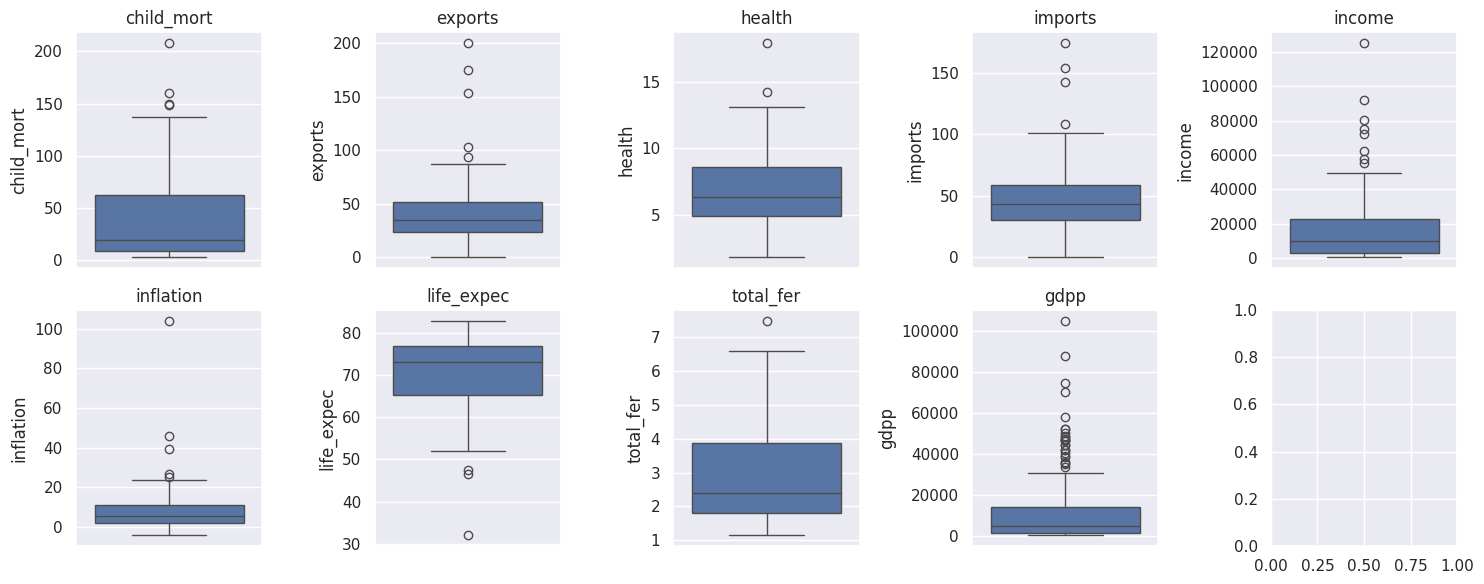

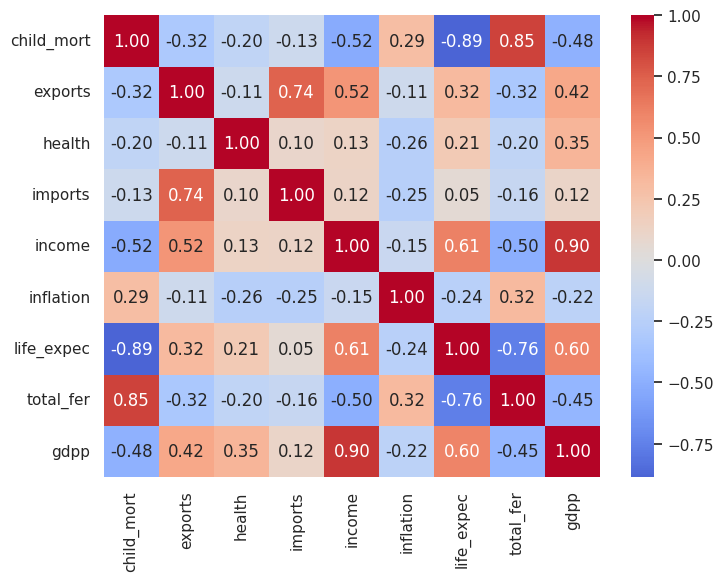

In [11]:
display(paises.describe().T)
print("Nulos totales:", paises.isna().sum().sum())

nums = paises.drop(columns="country").columns
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for a, c in zip(ax.ravel(), nums):
    sns.boxplot(y=paises[c], ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(paises[nums].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Magnitudes distintas:** "gdpp" (PIB per cápita) e "income" van en miles o decenas de miles; "child_mort", "life_expec" e "inflation" van en decenas; "total_fer" en unidades pequeñas (1–7). "gdpp" dominaría una distancia euclidiana sin preparar los datos, seguida de "income"; el resto casi no pesaría.

También se ven correlaciones fuertes esperables: "child_mort" baja cuando "life_expec" e "income" suben. Hay variables que "cuentan lo mismo", algo a recordar al interpretar.

## Paso 3 · Preparar: dos matrices

In [12]:
X_raw = sub.copy()                                                    # valores originales
X_std = pd.DataFrame(StandardScaler().fit_transform(sub), index=sub.index, columns=sub.columns)  # estandarizados
etiquetas = list(sub.index)                                           # nombres de países, aparte de la matriz
print(X_std.agg(["mean", "std"]).round(2).iloc[:, :4])

      child_mort  exports  health  imports
mean        0.00     0.00    0.00     0.00
std         1.02     1.02    1.02     1.02


**Predicción:** sin estandarizar, el dendrograma quedará ordenado casi solo por "gdpp" e "income" (países ricos separados de los demás), y Chile se juntará con países parecidos en PIB per cápita. Al estandarizar, pesarán todas las variables (salud, fertilidad, mortalidad) y las agrupaciones deberían cambiar.

## Paso 4 · Construir la jerarquía y leer el dendrograma
"ward" solo admite distancia euclidiana, que es la que usa "linkage" por defecto con una matriz de datos.

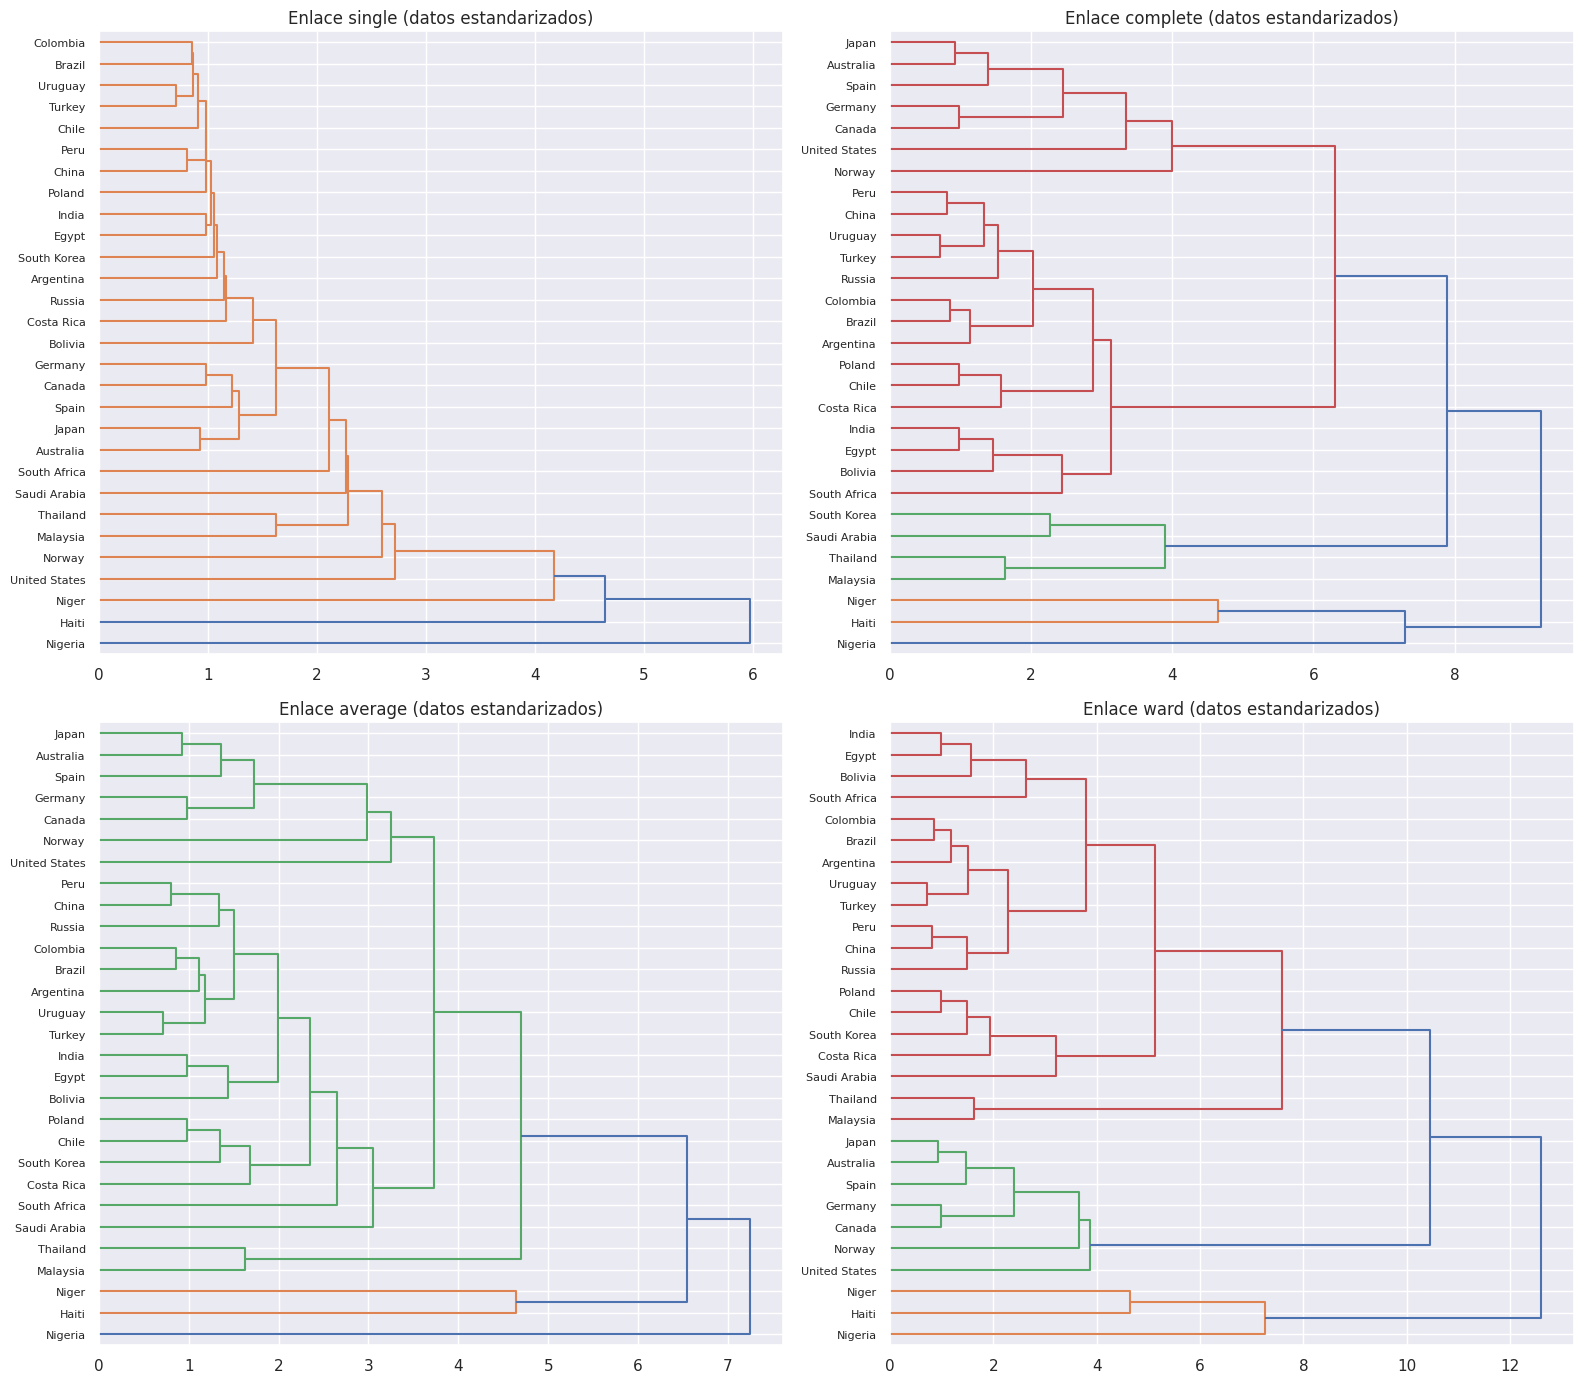

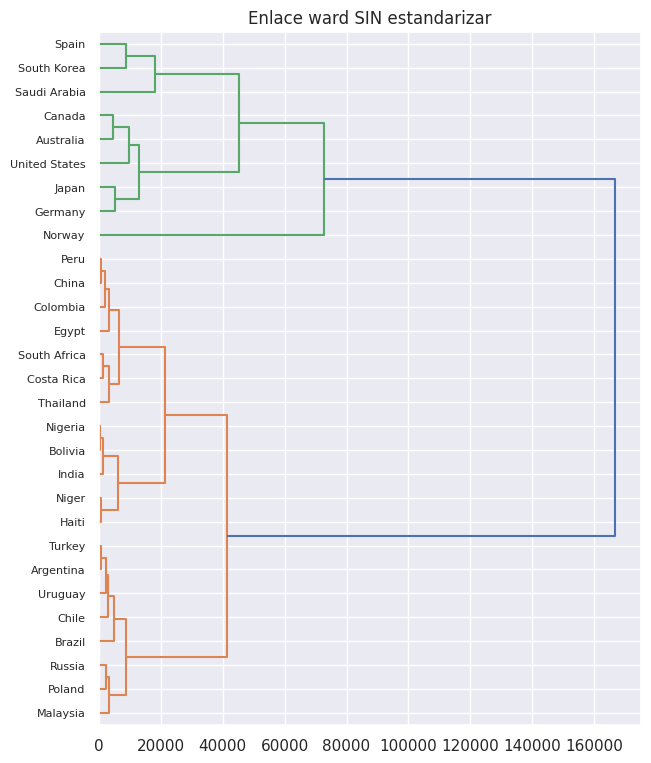

cophenet single: 0.864
cophenet complete: 0.789
cophenet average: 0.886
cophenet ward: 0.774


In [13]:
metodos = ["single", "complete", "average", "ward"]
Zs = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, m in zip(axes.ravel(), metodos):
    Zs[m] = linkage(X_std, method=m)
    dendrogram(Zs[m], labels=etiquetas, orientation="right", ax=ax, leaf_font_size=8)
    ax.set_title(f"Enlace {m} (datos estandarizados)")
plt.tight_layout(); plt.show()

# Mismo enlace (ward) sin estandarizar
Z_raw = linkage(X_raw, method="ward")
plt.figure(figsize=(7, 9))
dendrogram(Z_raw, labels=etiquetas, orientation="right", leaf_font_size=8)
plt.title("Enlace ward SIN estandarizar"); plt.show()

# Qué tan fiel es cada dendrograma a las distancias originales
for m in metodos:
    c, _ = cophenet(Zs[m], pdist(X_std))
    print(f"cophenet {m}: {c:.3f}")

**Diferencias de forma:**
- single: forma de «cadena»: va pegando un país a la vez al grupo grande; es difícil ver grupos claros.
- complete y average: grupos más compactos y equilibrados; average queda entre single y complete.
- ward: grupos más parejos en tamaño y cortes más claros, porque junta los grupos que menos aumentan la varianza interna.

Sin estandarizar: el árbol cambia bastante: separa casi solo según "gdpp"/"income", tal como se predijo. Al estandarizar, la estructura refleja también salud y fertilidad.

## Paso 5 · Cortar la jerarquía
Se elige **ward sobre datos estandarizados**: da grupos compactos y fáciles de describir.

Últimas 8 alturas de fusión: [ 3.8   3.87  4.65  5.12  7.25  7.59 10.44 12.6 ]


,k,silueta,tamaños,salto_de_altura
0,2,0.498,"[3, 26]",2.16
1,3,0.330,"[3, 7, 19]",2.85
2,4,0.365,"[3, 7, 2, 17]",0.34
3,5,0.376,"[2, 1, 7, 2, 17]",2.13


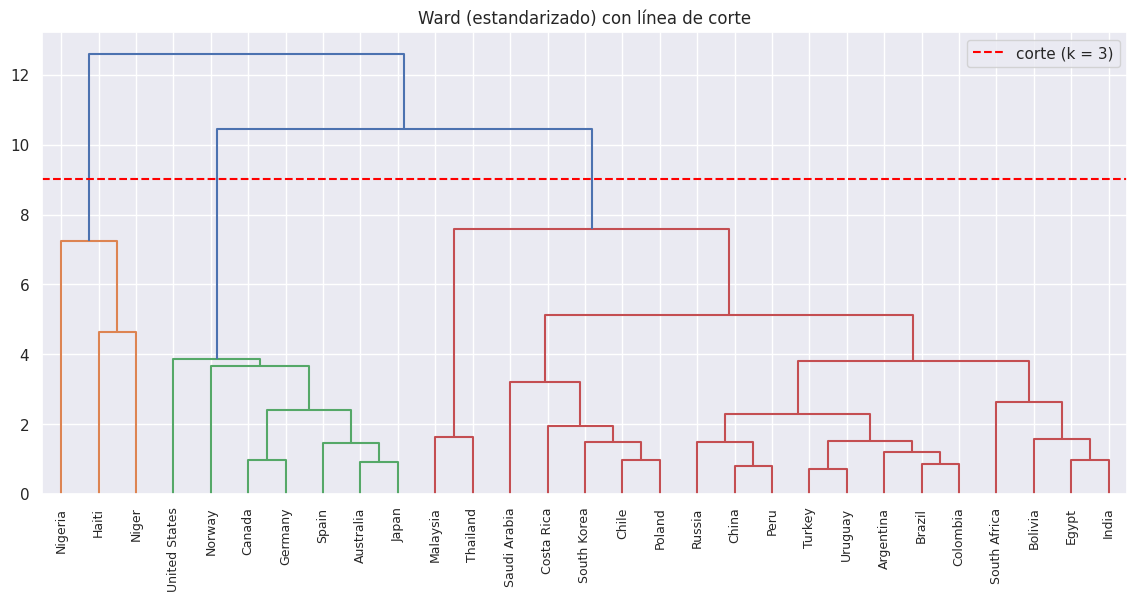

In [14]:
Z = Zs["ward"]
print("Últimas 8 alturas de fusión:", np.round(Z[-8:, 2], 2))

filas = []
for k in [2, 3, 4, 5]:
    lab = fcluster(Z, k, criterion="maxclust")
    filas.append({
        "k": k,
        "silueta": round(silhouette_score(X_std, lab), 3),
        "tamaños": np.bincount(lab)[1:].tolist(),
        "salto_de_altura": round(Z[-(k - 1), 2] - Z[-k, 2], 2),   # cuánto cuesta pasar de k a k-1 grupos
    })
display(pd.DataFrame(filas))

K2 = 3
corte = (Z[-K2, 2] + Z[-(K2 - 1), 2]) / 2
plt.figure(figsize=(14, 6))
dendrogram(Z, labels=etiquetas, leaf_rotation=90, leaf_font_size=9)
plt.axhline(corte, color="red", ls="--", label=f"corte (k = {K2})")
plt.legend(); plt.title("Ward (estandarizado) con línea de corte"); plt.show()

Corte elegido: k = 3. Evidencias:
1. Saltos de altura: hay un salto grande al pasar de 3 a 2 grupos, es decir, juntar esos dos grupos obliga a mezclar países muy distintos.
2. Silueta: el corte con 3 grupos tiene una silueta razonable comparada con 4 o 5.
3. Utilidad: tres grupos se pueden describir simple (ingreso y salud altos / intermedios / bajos); con 4 o 5 aparecen grupos muy pequeños.


## Paso 6 · Interpretar y comparar con K-means

In [15]:
sub["cluster_jer"] = fcluster(Z, K2, criterion="maxclust")

for g, d in sub.groupby("cluster_jer"):
    print(f"Grupo {g} ({len(d)} países):", ", ".join(sorted(d.index)))

perfil2 = sub.groupby("cluster_jer").mean().round(1)       # promedios en unidades originales
display(perfil2)

g_chile = sub.loc["Chile", "cluster_jer"]
print("Chile está en el grupo", g_chile, "junto a:", sorted(sub[sub["cluster_jer"] == g_chile].index.drop("Chile")))

# Comparación con K-means (mismo k, datos estandarizados)
km2 = KMeans(n_clusters=K2, n_init=10, random_state=SEED).fit(X_std)
sub["cluster_km"] = km2.labels_
print(pd.crosstab(sub["cluster_jer"], sub["cluster_km"], rownames=["jerárquico"], colnames=["K-means"]))
print("ARI jerárquico vs. K-means:", round(adjusted_rand_score(sub["cluster_jer"], sub["cluster_km"]), 3))

Grupo 1 (3 países): Haiti, Niger, Nigeria
Grupo 2 (7 países): Australia, Canada, Germany, Japan, Norway, Spain, United States
Grupo 3 (19 países): Argentina, Bolivia, Brazil, Chile, China, Colombia, Costa Rica, Egypt, India, Malaysia, Peru, Poland, Russia, Saudi Arabia, South Africa, South Korea, Thailand, Turkey, Uruguay


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster_jer,,,,,,,,,
1,153.7,20.9,5.7,43.7,2488.0,37.3,50.5,5.6,1113.3
2,4.6,26.3,11.1,24.8,43214.3,1.5,81.1,1.7,50357.1
3,20.2,34.3,6.5,31.5,16740.5,8.2,74.1,2.1,9110.0


Chile está en el grupo 3 junto a: ['Argentina', 'Bolivia', 'Brazil', 'China', 'Colombia', 'Costa Rica', 'Egypt', 'India', 'Malaysia', 'Peru', 'Poland', 'Russia', 'Saudi Arabia', 'South Africa', 'South Korea', 'Thailand', 'Turkey', 'Uruguay']
K-means     0   1  2
jerárquico          
1           0   0  3
2           7   0  0
3           0  19  0
ARI jerárquico vs. K-means: 1.0


Chile queda en el grupo 3 (19 países), junto a Argentina, Bolivia, Brazil, China, Colombia, Costa Rica, Egypt, India, Malaysia, Peru, Poland, Russia, Saudi Arabia, South Africa, South Korea, Thailand, Turkey y Uruguay. Es un grupo intermedio: mortalidad infantil de 20, esperanza de vida de 74 años y PIB per cápita de 9.110. Se separa del grupo 2 (Australia, Canada, Germany, Japan, Norway, Spain, United States), con ingreso y PIB per cápita mucho más altos, y del grupo 1 (Haiti, Niger, Nigeria), con mortalidad de 154 y esperanza de vida de 50. Mi hipótesis se cumplió en parte: Uruguay, Argentina, Costa Rica, Malaysia, Turkey y Poland quedaron con Chile y no se mezcló con los extremos. Pero el grupo es muy amplio y también incluye a China, India, Russia y Saudi Arabia.

Jerárquico vs. K-means: el ARI es 1,0, es decir, ambos métodos producen la misma partición (solo cambian los números de las etiquetas). Esto es coherente porque ward y K-means buscan grupos compactos, con poca varianza interna. Presentaría el dendrograma porque muestra los niveles intermedios, no solo 3 grupos.

Limitación: 19 de 29 países quedan en un solo grupo, así que k=3 no distingue bien entre países intermedios. El resultado depende de los países elegidos a mano, de las variables, de la estandarización y de la distancia euclidiana. Un grupo no es un ranking ni un juicio de valor sobre un país.

# Cierre: las tres preguntas

1. **¿Qué idea de «grupo» usa cada método?** K-means: grupos compactos alrededor de un centroide, con k fijado de antemano. Jerárquico: grupos anidados que se forman por cercanía, sin fijar k hasta cortar el árbol.
2. **¿Qué decisiones de representación cambiaron los resultados?** Sobre todo la **escala**: en el ejercicio 2, estandarizar cambió la estructura del dendrograma; en el 1 casi no importó porque los rangos eran parecidos. También importaron qué variables entran (se excluyó "CustomerID" y "Gender") y el tipo de enlace.
3. **¿Qué grupos usaría para decidir?** Los segmentos de clientes, para probar acciones de comunicación (no como verdad definitiva), y el grupo de Chile solo como referencia exploratoria, no para evaluar o comparar países en valor.